# AUC and tPeak for the stimulus-duration recordings

Reads the HDF5 file made by `organize_stimlengths_to_hdf5`, calculates the AUC and tPeak of every neuron for Ca, HyLight (`hylight` or `hylight2`) and the HyLight 920/800 ratio (`hylight920800ratio` or `hylight2920800ratio`), and plots them by stimulus duration.

**AUC** (`compute_auc`, section 3), for each neuron:
1. The trace is low-pass filtered at its own imaging frequency (4 Hz, 4th-order Butterworth, zero-phase).
2. From the end of the stimulus (1 s + stimulus duration), the first zero crossing of the filtered trace is found. If there is none, the end of the recording is used.
3. The absolute value of the filtered trace is integrated from stimulus onset (1 s) to that point: AUC = ∫|trace| dt, so positive and negative parts both add to the area.

The result is the column `AUC_absolute_onset_to_zero_after_offset`.

**AUC relative to Ca** (`make_paired_auc_df`): each HyLight (or 920/800 ratio) neuron is paired with the Ca trace in the same row of the same fly, compartment and stimulus duration. The table has `AUC_ca`, `AUC_hylight` and `AUC_ratio` = `AUC_hylight` / `AUC_ca`.

**tPeak** (`compute_tpeak`, section 4), for each neuron:
1. The trace is low-pass filtered as for AUC.
2. Baseline: the median of the filtered trace in the 1 s before stimulus onset.
3. The peak is the largest positive baseline-corrected value from stimulus onset until 15 s after the end of the stimulus (or the end of the recording).
4. The neuron counts as a responder if this peak is at least 0.06 and at least 1 × the baseline noise (1.4826 × median absolute deviation).
5. For responders, `tpeak_s` is the peak time from stimulus onset; for non-responders it is NaN.
6. The first positive inflection (first depolarization) is the first local maximum of the slope that is above 4 × the baseline slope noise, before the peak (`t_first_depolarization_s` from stimulus onset; `first_positive_inflection_time_s` from the start of the recording).

**Plots** (section 6): `plot_auc_by_stim_time_xaxis` plots any of these columns by stimulus duration, and `plot_hylight_auc_vs_ca_auc` plots HyLight AUC against Ca AUC for each neuron.

**How to use:** set `H5_FILE` and `HYLIGHT_SENSOR` in section 1, then run all cells.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator
from scipy.signal import butter, sosfiltfilt, find_peaks

try:
    from scipy import stats as _scipy_stats
except ImportError:
    _scipy_stats = None

try:
    from IPython.display import display
except ImportError:
    display = print

## 1. Settings

In [38]:
H5_FILE = Path("your/path/here/durationseries-hylight2.h5")

# "hylight" or "hylight2": which HyLight recordings to analyze.
HYLIGHT_SENSOR = "hylight2"
HYLIGHT_LABEL = "HYlight2"                         # used in axis labels

RATIO_SENSOR = f"{HYLIGHT_SENSOR}920800ratio"      # HyLight 920/800 ratio (ΔR/R)
CA_SENSOR = "ca"

# Sensors to calculate AUC and tPeak for.
SENSORS = [CA_SENSOR, HYLIGHT_SENSOR, RATIO_SENSOR]

# Conditions in the order they are plotted.
GENOTYPES = ["CTR", "PFKRi", "TNT"]

COMPARTMENT = "M9"

AUC_COL = "AUC_absolute_onset_to_zero_after_offset"

## 2. Load the data

In [39]:
# Traces loaded from the HDF5 file, looked up by the "path" key in files_df.
TRACE_ARRAYS = {}


def load_files_df_from_hdf5(h5_file):
    """
    Read the HDF5 file made by organize_stimlengths_to_hdf5 and return a table
    with one row per recording: path, genotype, subfolder (compartment),
    series_id, sensor, stim_label, stim_time, frequency and n_traces.

    "path" is a key of the form "<file>::<dataset>"; read_traces() returns
    the stored traces (rows = neurons, columns = time points).
    """
    TRACE_ARRAYS.clear()
    rows = []
    with h5py.File(h5_file, "r") as f:
        for fly_id, fly in f.items():
            condition = fly.attrs["condition"]
            for compartment, comp in fly.items():
                for sensor, sensor_group in comp.items():
                    for stim_name, dset in sensor_group.items():
                        key = f"{h5_file}::{dset.name}"
                        TRACE_ARRAYS[key] = dset[:]
                        rows.append({
                            "path": key,
                            "genotype": condition,
                            "subfolder": compartment,
                            "series_id": fly_id,
                            "sensor": sensor,
                            "stim_label": dset.attrs["stim_label"],
                            "stim_time": float(dset.attrs["stim_time"]),
                            "frequency": float(dset.attrs["imaging_frequency"]),
                            "n_traces": dset.shape[0],
                        })
    return pd.DataFrame(rows)


def read_traces(path):
    """Traces of one recording: rows = neurons, columns = time points."""
    return np.array(TRACE_ARRAYS[path], dtype=float)


def summarize_files_df(files_df):
    """Number of flies and neurons per condition, compartment, sensor and duration."""
    return (files_df
            .groupby(["genotype", "subfolder", "sensor", "stim_time"])
            .agg(n_flies=("series_id", "nunique"),
                 n_neurons=("n_traces", "sum"),
                 missing_frequency=("frequency", lambda s: int(s.isna().sum())))
            .reset_index())

In [40]:
files_df = load_files_df_from_hdf5(H5_FILE)
print("Sensors in the file:", sorted(files_df["sensor"].unique()))

missing_sensors = [s for s in SENSORS if s not in set(files_df["sensor"])]
if missing_sensors:
    print(f"Not in the file (check HYLIGHT_SENSOR): {missing_sensors}")

analysis_df = files_df[files_df["sensor"].isin(SENSORS)].reset_index(drop=True)
summarize_files_df(analysis_df)

Sensors in the file: ['ca', 'hy800', 'hylight2', 'hylight2920800ratio']


,genotype,subfolder,sensor,stim_time,n_flies,n_neurons,missing_frequency
0,CTR,M9,ca,0.49,15,83,0
1,CTR,M9,ca,0.99,15,83,0
2,CTR,M9,ca,1.99,15,83,0
3,CTR,M9,ca,3.99,15,83,0
4,CTR,M9,ca,7.99,15,83,0
5,CTR,M9,hylight2,0.49,10,54,0
6,CTR,M9,hylight2,0.99,10,54,0
7,CTR,M9,hylight2,1.99,10,54,0
8,CTR,M9,hylight2,3.99,10,54,0
9,CTR,M9,hylight2,7.99,10,54,0


## 3. AUC

In [41]:
# ============================================================
# Shared trace processing (used for AUC and tPeak)
# ============================================================

def interpolate_nonfinite(trace):
    """Fill NaN samples by linear interpolation (ends: nearest value), so the filter can run."""
    trace = np.asarray(trace, dtype=float)
    finite = np.isfinite(trace)
    if not finite.any():
        return np.full(trace.size, np.nan)
    if finite.all():
        return trace.copy()
    idx = np.arange(trace.size)
    out = trace.copy()
    out[~finite] = np.interp(idx[~finite], idx[finite], trace[finite])
    return out


def lowpass_filter(trace, frequency, cutoff_hz=4.0, order=4):
    """
    Zero-phase Butterworth low-pass filter at the recording's own imaging
    frequency. The output has the same samples as the input.
    """
    trace = np.asarray(trace, dtype=float)
    n = trace.size
    if n == 0:
        return trace.copy()
    if cutoff_hz >= frequency / 2:
        raise ValueError(f"cutoff {cutoff_hz} Hz must be below half the imaging frequency ({frequency / 2:.2f} Hz)")
    if not np.isfinite(trace).any():
        return np.full(n, np.nan)

    filled = interpolate_nonfinite(trace)
    sos = butter(N=int(order), Wn=float(cutoff_hz), btype="lowpass", fs=float(frequency), output="sos")
    default_padlen = 3 * (2 * len(sos) + 1 - min(np.sum(sos[:, 2] == 0), np.sum(sos[:, 5] == 0)))
    padlen = min(int(default_padlen), n - 1)
    if n < 3 or padlen < 1:
        return filled
    return sosfiltfilt(sos, filled, padlen=padlen)


def _print_failures(failures):
    if failures:
        print(f"\n{len(failures)} recording(s) skipped:")
        for where, reason in failures:
            print(f"  {where}: {reason}")

In [42]:
# np.trapezoid in NumPy >= 2.0, np.trapz before.
_trapezoid = getattr(np, "trapezoid", None) or np.trapz


def _time_to_idx(time_s, frequency, n):
    """Nearest sample index for a time in seconds."""
    return int(np.clip(int(round(float(time_s) * float(frequency))), 0, n - 1))


def _sign_with_deadband(value, deadband):
    if not np.isfinite(value) or abs(value) <= deadband:
        return 0
    return int(np.sign(value))


def first_zero_crossing_after(trace, start_idx, frequency, deadband=0.0, min_persist_ms=0.0):
    """
    First zero crossing at or after start_idx: the trace enters the deadband
    around zero, or changes sign. With min_persist_ms > 1 sample, the new sign
    must last that long. Returns (index, found); index is the last sample
    when no crossing is found.
    """
    trace = np.asarray(trace, dtype=float)
    n = trace.size
    if n == 0:
        return 0, False

    start_idx = int(np.clip(start_idx, 0, n - 1))
    persist_samples = (max(1, int(np.ceil(min_persist_ms / 1000.0 * float(frequency))))
                       if min_persist_ms > 0 else 0)

    # First signed sample at or after the start.
    i0 = start_idx
    previous_sign = _sign_with_deadband(trace[i0], deadband)
    while previous_sign == 0 and i0 < n - 1:
        i0 += 1
        previous_sign = _sign_with_deadband(trace[i0], deadband)
    if previous_sign == 0:
        return n - 1, False

    for i in range(i0, n - 1):
        current = _sign_with_deadband(trace[i], deadband)
        nxt = _sign_with_deadband(trace[i + 1], deadband)

        if current != 0 and (nxt == 0 or nxt != current):
            candidate = i + 1
        else:
            if current != 0:
                previous_sign = current
            continue

        if persist_samples <= 1:
            return candidate, True

        # Skip samples inside the deadband, then check that the new sign lasts.
        k = candidate
        while k < n and _sign_with_deadband(trace[k], deadband) == 0:
            k += 1
        if k >= n:
            return n - 1, False
        new_sign = _sign_with_deadband(trace[k], deadband)
        if new_sign == previous_sign:
            continue
        end = min(n, k + persist_samples)
        if all(_sign_with_deadband(trace[j], deadband) == new_sign for j in range(k, end)):
            return candidate, True

    return n - 1, False


def compute_auc(
    files_df,
    stim_start=1.0,
    auc_integration_start=None,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    deadband=0.0,
    min_persist_ms=1.0,
    baseline_correct=False,
    baseline_window=(0.0, 1.0),
    auc_col="AUC_absolute_onset_to_zero_after_offset",
):
    """
    Absolute AUC of every neuron in every recording of files_df.

    For each trace: low-pass filter; find the first zero crossing after the
    end of the stimulus (stim_start + stim_time); integrate |filtered trace|
    from auc_integration_start (default: stim_start) to that crossing, or to
    the end of the recording when there is none.

    Returns one row per neuron (trace_i = row in the recording).
    """
    if auc_integration_start is None:
        auc_integration_start = stim_start

    rows, failures = [], []

    for _, meta in files_df.iterrows():
        where = f"{meta['series_id']} {meta['subfolder']} {meta['sensor']} {meta['stim_time']:g} s"
        frequency = float(meta["frequency"])
        stim_time = float(meta["stim_time"])

        if not np.isfinite(frequency) or frequency <= 0:
            failures.append((where, f"invalid imaging frequency {frequency}"))
            continue
        if lowpass_cutoff_hz >= frequency / 2:
            failures.append((where, f"cutoff {lowpass_cutoff_hz} Hz is not below half the imaging frequency"))
            continue

        zero_start_time = stim_start + stim_time
        traces = read_traces(meta["path"])

        for trace_i, trace in enumerate(traces):
            out = {
                "trace_i": trace_i,
                "genotype": meta["genotype"],
                "subfolder": meta["subfolder"],
                "series_id": meta["series_id"],
                "sensor": meta["sensor"],
                "stim_label": meta["stim_label"],
                "stim_time": stim_time,
                "frequency_hz": frequency,
                "stim_offset_time_s": zero_start_time,
                "integration_end_time_s": np.nan,
                "detected_zero_crossing_time_s": np.nan,
                "zero_crossing_found": False,
                "baseline_value": np.nan,
                auc_col: np.nan,
            }

            if np.isfinite(trace).sum() >= 2:
                filtered = lowpass_filter(trace, frequency, lowpass_cutoff_hz, filter_order)
                n = filtered.size

                if baseline_correct:
                    b0 = _time_to_idx(baseline_window[0], frequency, n)
                    b1 = _time_to_idx(baseline_window[1], frequency, n)
                    if b1 <= b0:
                        b1 = min(n, b0 + 1)
                    out["baseline_value"] = np.nanmean(filtered[b0:b1])
                    filtered = filtered - out["baseline_value"]

                zero_start_idx = _time_to_idx(zero_start_time, frequency, n)
                crossing_idx, found = first_zero_crossing_after(
                    filtered, zero_start_idx, frequency, deadband, min_persist_ms
                )

                auc_start_idx = _time_to_idx(auc_integration_start, frequency, n)
                stop_idx = min(max(crossing_idx, auc_start_idx), n - 1)

                segment = filtered[auc_start_idx:stop_idx + 1]
                segment = np.abs(segment[np.isfinite(segment)])
                if segment.size >= 2:
                    out[auc_col] = float(_trapezoid(segment, dx=1.0 / frequency))

                out["integration_end_time_s"] = stop_idx / frequency
                out["zero_crossing_found"] = bool(found)
                if found:
                    out["detected_zero_crossing_time_s"] = crossing_idx / frequency

            rows.append(out)

    _print_failures(failures)
    return pd.DataFrame(rows)


def make_paired_auc_df(
    auc_df,
    hylight_sensor,
    ca_sensor="ca",
    auc_col="AUC_absolute_onset_to_zero_after_offset",
    round_stim_to=0.5,
    min_denominator_abs=1e-12,
):
    """
    Pair each HyLight (or HyLight 920/800 ratio) neuron with the Ca trace in
    the same row (trace_i) of the same condition, compartment, fly and
    stimulus duration.

    Returns one row per pair with AUC_ca, AUC_hylight and
    AUC_ratio = AUC_hylight / AUC_ca. The column sensor is
    "<hylight_sensor>_over_<ca_sensor>".
    """
    d = auc_df[auc_df["sensor"].isin([hylight_sensor, ca_sensor])].copy()
    d[auc_col] = pd.to_numeric(d[auc_col], errors="coerce")
    d = d[np.isfinite(d[auc_col])]
    if d.empty:
        raise ValueError(f"No AUC values for {hylight_sensor!r} or {ca_sensor!r}.")

    d["stim_time"] = np.round(d["stim_time"].astype(float) / round_stim_to) * round_stim_to
    d["role"] = np.where(d["sensor"] == ca_sensor, "AUC_ca", "AUC_hylight")

    keys = ["genotype", "subfolder", "series_id", "stim_time", "trace_i"]
    paired = d.pivot_table(index=keys, columns="role", values=auc_col, aggfunc="mean").reset_index()
    paired.columns.name = None
    for col in ("AUC_ca", "AUC_hylight"):
        if col not in paired.columns:
            paired[col] = np.nan

    n_no_hylight = int((np.isfinite(paired["AUC_ca"]) & ~np.isfinite(paired["AUC_hylight"])).sum())
    n_no_ca = int((~np.isfinite(paired["AUC_ca"]) & np.isfinite(paired["AUC_hylight"])).sum())
    paired = paired[np.isfinite(paired["AUC_ca"]) & np.isfinite(paired["AUC_hylight"])].copy()

    denominator = paired["AUC_ca"].where(paired["AUC_ca"].abs() >= min_denominator_abs)
    paired["AUC_ratio"] = paired["AUC_hylight"] / denominator
    paired["sensor"] = f"{hylight_sensor}_over_{ca_sensor}"
    paired["hylight_sensor"] = hylight_sensor
    paired["stim_time_rounded"] = paired["stim_time"]

    print(f"{hylight_sensor} / {ca_sensor}: {len(paired)} paired neurons; "
          f"{n_no_hylight} {ca_sensor} neurons without a {hylight_sensor} partner "
          f"(e.g. flies recorded with another HyLight version), "
          f"{n_no_ca} {hylight_sensor} neurons without a {ca_sensor} partner")
    return paired.reset_index(drop=True)

In [43]:
auc_df = compute_auc(
    analysis_df,
    stim_start=1.0,
    auc_integration_start=1.0,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    deadband=0.0,
    min_persist_ms=1.0,
    baseline_correct=False,
    auc_col=AUC_COL,
)

# HyLight and HyLight 920/800 ratio, each paired with Ca of the same neurons.
paired_hylight_df = make_paired_auc_df(auc_df, HYLIGHT_SENSOR, CA_SENSOR, auc_col=AUC_COL)
paired_ratio_df = make_paired_auc_df(auc_df, RATIO_SENSOR, CA_SENSOR, auc_col=AUC_COL)

(auc_df.groupby(["genotype", "subfolder", "sensor", "stim_time"])
       .agg(neurons=(AUC_COL, "count"),
            zero_crossing_found=("zero_crossing_found", "sum"))
       .reset_index())

hylight2 / ca: 270 paired neurons; 145 ca neurons without a hylight2 partner (e.g. flies recorded with another HyLight version), 0 hylight2 neurons without a ca partner
hylight2920800ratio / ca: 145 paired neurons; 270 ca neurons without a hylight2920800ratio partner (e.g. flies recorded with another HyLight version), 0 hylight2920800ratio neurons without a ca partner


,genotype,subfolder,sensor,stim_time,neurons,zero_crossing_found
0,CTR,M9,ca,0.49,83,83
1,CTR,M9,ca,0.99,83,83
2,CTR,M9,ca,1.99,83,83
3,CTR,M9,ca,3.99,83,82
4,CTR,M9,ca,7.99,83,83
5,CTR,M9,hylight2,0.49,54,53
6,CTR,M9,hylight2,0.99,54,49
7,CTR,M9,hylight2,1.99,54,50
8,CTR,M9,hylight2,3.99,54,51
9,CTR,M9,hylight2,7.99,54,49


## 4. tPeak

In [44]:
def _baseline_stats(values, times, stimulus_onset, window):
    """Median and robust noise (1.4826 x MAD, or SD if MAD = 0) in a window relative to stimulus onset."""
    values = np.asarray(values, dtype=float)
    rel = np.asarray(times, dtype=float) - float(stimulus_onset)
    start, end = window
    mask = np.isfinite(values) & np.isfinite(rel)
    if start is not None:
        mask &= rel >= float(start)
    if end is not None:
        mask &= rel < float(end)
    v = values[mask]
    if v.size == 0:
        return 0.0, np.nan
    center = float(np.nanmedian(v))
    noise = 1.4826 * float(np.nanmedian(np.abs(v - center)))
    if noise == 0 and v.size > 1:
        noise = float(np.nanstd(v, ddof=1))
    return center, noise


def _sensor_setting(setting, sensor):
    """A number used for every sensor, or a dict {sensor name: number}."""
    if setting is None:
        return None
    if np.isscalar(setting):
        return float(setting)
    value = {str(k).lower(): v for k, v in setting.items()}.get(str(sensor).lower())
    return None if value is None else float(value)


def compute_tpeak(
    files_df,
    stim_start=1.0,
    peak_search_start_rel_onset=0.0,
    peak_search_end_rel_offset=15.0,
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    peak_direction="positive",
    baseline_window=(-1.0, 0.0),
    sensor_min_peak=0.06,
    min_snr=1.0,
    inflection_search_start_rel_onset=None,
    inflection_search_end_rel_offset=None,
    inflection_min_slope=None,
    inflection_min_slope_snr=4.0,
    inflection_only_for_responders=True,
    inflection_must_precede_positive_peak=True,
):
    """
    Peak, tPeak, responder status and first positive inflection of every
    neuron in every recording of files_df.

    Peak search: from stimulus onset + peak_search_start_rel_onset to
    stimulus offset + peak_search_end_rel_offset (or the end of the recording;
    None searches to the end). The inflection search uses the same window
    unless its own limits are given.

    Responder: the baseline-corrected peak is at least sensor_min_peak and at
    least min_snr x baseline noise. sensor_min_peak and inflection_min_slope
    can be one number for all sensors or a dict {sensor name: number}.
    tpeak_s (from stimulus onset) is NaN for non-responders.
    """
    if peak_direction not in ("absolute", "positive", "negative"):
        raise ValueError("peak_direction must be 'absolute', 'positive' or 'negative'.")
    if inflection_search_start_rel_onset is None:
        inflection_search_start_rel_onset = peak_search_start_rel_onset
    if inflection_search_end_rel_offset is None:
        inflection_search_end_rel_offset = peak_search_end_rel_offset

    rows, failures = [], []

    for _, meta in files_df.iterrows():
        where = f"{meta['series_id']} {meta['subfolder']} {meta['sensor']} {meta['stim_time']:g} s"
        frequency = float(meta["frequency"])
        stim_time = float(meta["stim_time"])

        if not np.isfinite(frequency) or frequency <= 0:
            failures.append((where, f"invalid imaging frequency {frequency}"))
            continue
        if lowpass_cutoff_hz >= frequency / 2:
            failures.append((where, f"cutoff {lowpass_cutoff_hz} Hz is not below half the imaging frequency"))
            continue

        onset = float(stim_start)
        offset = onset + stim_time
        peak_start = onset + float(peak_search_start_rel_onset)
        peak_end_requested = (None if peak_search_end_rel_offset is None
                              else offset + float(peak_search_end_rel_offset))
        infl_start = onset + float(inflection_search_start_rel_onset)
        infl_end_requested = (None if inflection_search_end_rel_offset is None
                              else offset + float(inflection_search_end_rel_offset))

        min_peak = _sensor_setting(sensor_min_peak, meta["sensor"])
        min_slope = _sensor_setting(inflection_min_slope, meta["sensor"])

        traces = read_traces(meta["path"])

        for trace_i, trace in enumerate(traces):
            out = {
                "trace_i": trace_i,
                "genotype": meta["genotype"],
                "subfolder": meta["subfolder"],
                "series_id": meta["series_id"],
                "sensor": meta["sensor"],
                "stim_label": meta["stim_label"],
                "stim_time": stim_time,
                "frequency_hz": frequency,
                "peak_dff": np.nan,
                "peak_from_baseline_dff": np.nan,
                "tpeak_s": np.nan,
                "peak_time_s": np.nan,
                "tpeak_from_stimulus_offset_s": np.nan,
                "detected_direction": None,
                "is_responder": False,
                "response_threshold": np.nan,
                "baseline_center": np.nan,
                "baseline_noise": np.nan,
                "response_snr": np.nan,
                "t_first_depolarization_s": np.nan,
                "first_positive_inflection_time_s": np.nan,
                "first_positive_inflection_slope": np.nan,
                "has_positive_inflection": False,
            }

            if np.isfinite(trace).sum() < 2:
                rows.append(out)
                continue

            filtered = lowpass_filter(trace, frequency, lowpass_cutoff_hz, filter_order)
            times = np.arange(filtered.size) / frequency
            recording_end = float(times[-1])

            # ---------------- peak ----------------
            peak_end = recording_end if peak_end_requested is None else min(peak_end_requested, recording_end)
            center, noise = _baseline_stats(filtered, times, onset, baseline_window)
            out.update(baseline_center=center, baseline_noise=noise)
            corrected = filtered - center

            candidates = np.flatnonzero(np.isfinite(filtered) & (times >= peak_start) & (times <= peak_end))
            positive_peak_time = np.nan

            if peak_end >= peak_start and candidates.size:
                values = corrected[candidates]
                if peak_direction == "absolute":
                    k = int(np.argmax(np.abs(values)))
                elif peak_direction == "positive":
                    k = int(np.argmax(values))
                else:
                    k = int(np.argmin(values))
                p = int(candidates[k])
                peak = float(corrected[p])
                peak_time = float(times[p])

                thresholds = []
                if min_peak is not None:
                    thresholds.append(min_peak)
                if min_snr is not None and np.isfinite(noise):
                    thresholds.append(float(min_snr) * noise)
                threshold = max(thresholds) if thresholds else 0.0

                if not thresholds:
                    responder = True
                elif peak_direction == "absolute":
                    responder = abs(peak) >= threshold
                elif peak_direction == "positive":
                    responder = peak >= threshold
                else:
                    responder = peak <= -threshold

                if np.isfinite(noise) and noise > 0:
                    snr = abs(peak) / noise
                elif noise == 0 and abs(peak) > 0:
                    snr = np.inf
                else:
                    snr = np.nan

                direction = "positive" if peak > 0 else ("negative" if peak < 0 else "zero")
                out.update(
                    peak_dff=float(filtered[p]),
                    peak_from_baseline_dff=peak,
                    detected_direction=direction,
                    is_responder=bool(responder),
                    response_threshold=threshold,
                    response_snr=snr,
                )
                if responder:
                    out.update(
                        tpeak_s=peak_time - onset,
                        peak_time_s=peak_time,
                        tpeak_from_stimulus_offset_s=peak_time - offset,
                    )
                    if direction == "positive":
                        positive_peak_time = peak_time

            # ---------------- first positive inflection ----------------
            infl_end = recording_end if infl_end_requested is None else min(infl_end_requested, recording_end)
            allow = out["is_responder"] if inflection_only_for_responders else True

            if filtered.size >= 3 and infl_end >= infl_start and allow:
                slope = np.gradient(filtered, times)
                s_center, s_noise = _baseline_stats(slope, times, onset, baseline_window)
                slope_corr = slope - s_center

                thresholds = []
                if min_slope is not None:
                    thresholds.append(min_slope)
                if inflection_min_slope_snr is not None and np.isfinite(s_noise):
                    thresholds.append(float(inflection_min_slope_snr) * s_noise)
                slope_threshold = max(thresholds) if thresholds else 0.0

                mask = (np.isfinite(filtered) & np.isfinite(slope_corr)
                        & (times >= infl_start) & (times <= infl_end))
                if inflection_must_precede_positive_peak and np.isfinite(positive_peak_time):
                    mask &= times <= positive_peak_time

                for_peaks = slope_corr.copy()
                for_peaks[~np.isfinite(for_peaks)] = -np.inf
                peak_idx, _ = find_peaks(for_peaks, height=max(0.0, slope_threshold))
                peak_idx = peak_idx[mask[peak_idx]]

                if peak_idx.size:
                    j = int(peak_idx[0])
                    out.update(
                        t_first_depolarization_s=float(times[j]) - onset,
                        first_positive_inflection_time_s=float(times[j]),
                        first_positive_inflection_slope=float(slope_corr[j]),
                        has_positive_inflection=True,
                    )

            rows.append(out)

    _print_failures(failures)
    return pd.DataFrame(rows)

In [45]:
tpeak_df = compute_tpeak(
    analysis_df,
    stim_start=1.0,
    peak_search_start_rel_onset=0.0,    # search begins at stimulus onset
    peak_search_end_rel_offset=15.0,    # and ends 15 s after the stimulus ends
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    peak_direction="positive",
    baseline_window=(-1.0, 0.0),
    sensor_min_peak=0.06,               # or e.g. {"ca": 0.12, "hylight2": 0.06, "hylight2920800ratio": 0.06}
    min_snr=1.0,
    inflection_min_slope=None,
    inflection_min_slope_snr=4.0,
    inflection_only_for_responders=True,
    inflection_must_precede_positive_peak=True,
)

(tpeak_df.groupby(["genotype", "subfolder", "sensor", "stim_time"])
         .agg(neurons=("trace_i", "size"),
              responders=("is_responder", "sum"),
              with_inflection=("has_positive_inflection", "sum"))
         .reset_index())

,genotype,subfolder,sensor,stim_time,neurons,responders,with_inflection
0,CTR,M9,ca,0.49,83,83,68
1,CTR,M9,ca,0.99,83,83,70
2,CTR,M9,ca,1.99,83,83,73
3,CTR,M9,ca,3.99,83,83,72
4,CTR,M9,ca,7.99,83,83,75
5,CTR,M9,hylight2,0.49,54,53,11
6,CTR,M9,hylight2,0.99,54,54,9
7,CTR,M9,hylight2,1.99,54,54,14
8,CTR,M9,hylight2,3.99,54,54,14
9,CTR,M9,hylight2,7.99,54,53,17


## 5. Plot functions
`plot_auc_by_stim_time_xaxis` plots any column of `auc_df`, `tpeak_df` or a paired table (`auc_col`) by stimulus duration. Points are neurons; the markers show the mean ± SEM. `plot_hylight_auc_vs_ca_auc` plots `AUC_hylight` against `AUC_ca` of a paired table.

In [46]:
def plot_auc_by_stim_time_xaxis(
    auc_df,
    sensor=None,
    subfolder=None,
    subfolders=None,
    genotype=None,
    genotypes=None,
    group_col="genotype",
    group_order=None,
    genotype_order=None,
    subfolder_order=None,
    colors=None,
    auc_col="AUC_absolute_onset_to_zero_after_offset",
    round_stim_to=0.5,
    stim_times=None,
    categorical_x=False,
    x_scale=None,
    show_points=True,
    show_sem=True,
    connect_means=True,
    show_legend=True,
    jitter_width=0.035,
    group_offset_width=0.16,
    genotype_offset_width=None,
    point_size=18,
    point_alpha=0.40,
    mean_marker_size=5.5,
    mean_marker_edgewidth=0.8,
    figsize=(4, 3),
    dpi=300,
    xlabel="Stimulus duration (s)",
    xtick_rotation=0,
    ylabel=None,
    title=None,
    ylim=None,
    xlim=None,
    savepath=None,
    # coloring options
    color_by="stim_time",  # "stim_time" or "group"
    stim_colormap="viridis",
    stim_colors=None,
    stim_color_reference_times=None,
    show_axis_lines=True,
    # stats options
    show_stats=False,
    control_group=None,
    control_genotype="CTR",
    stats_test="welch",
    p_adjust="holm",
    alpha=0.05,
    show_ns=False,
    stats_y_start=0.98,
    stats_y_step=0.07,
    stats_fontsize=12,
    yfontsize=12,
):
    """
    Plot AUC by stimulus duration.

    x_scale:
        "linear"      : x position is the stimulus duration itself, so spacing
                        on the axis is proportional to the real difference in
                        seconds (0.5 and 1 sit close together, 8 sits far right)
        "log"         : x position is log10(duration), so a doubling of
                        duration is always the same distance on the axis
        "categorical" : old behaviour, one evenly spaced slot per duration

        If x_scale is None it is taken from categorical_x
        (categorical_x=True -> "categorical", False -> "linear").

    xtick_rotation:
        Rotation of the x tick labels in degrees, 45 by default. Set it to 0
        for horizontal labels.

    jitter_width and group_offset_width are given as a fraction of the
    smallest gap between two neighbouring x positions, so they keep the same
    visual size whichever x_scale is used.

    color_by:
        "stim_time" : colors each stimulus duration using viridis
        "group"     : colors each genotype/subfolder/group using colors

    stim_color_reference_times:
        Optional list of stim durations used to define a consistent viridis scale
        across multiple plots. Example:
            stim_color_reference_times=[0.5, 1.0, 2.0, 4.0, 8.0]
    """

    if genotype_offset_width is not None:
        group_offset_width = genotype_offset_width

    if x_scale is None:
        x_scale = "categorical" if categorical_x else "linear"

    if x_scale not in ["categorical", "linear", "log"]:
        raise ValueError("x_scale must be 'categorical', 'linear' or 'log'.")

    if color_by not in ["stim_time", "group"]:
        raise ValueError("color_by must be either 'stim_time' or 'group'.")

    if auc_col not in auc_df.columns:
        raise ValueError(
            f"auc_col='{auc_col}' not found in auc_df. "
            f"Available columns are:\n{list(auc_df.columns)}"
        )

    if group_col not in auc_df.columns:
        raise ValueError(
            f"group_col='{group_col}' not found in auc_df. "
            f"Available columns are:\n{list(auc_df.columns)}"
        )

    d = auc_df.copy()

    d[auc_col] = pd.to_numeric(d[auc_col], errors="coerce")
    d = d[np.isfinite(d[auc_col])].copy()

    if sensor is not None:
        d = d[d["sensor"].astype(str).str.lower() == str(sensor).lower()].copy()

    if subfolder is not None:
        if "subfolder" not in d.columns:
            raise ValueError("You gave subfolder=..., but auc_df has no 'subfolder' column.")
        d = d[d["subfolder"].astype(str).str.lower() == str(subfolder).lower()].copy()

    if subfolders is not None:
        if "subfolder" not in d.columns:
            raise ValueError("You gave subfolders=..., but auc_df has no 'subfolder' column.")
        subfolder_set = {str(s).lower() for s in subfolders}
        d = d[d["subfolder"].astype(str).str.lower().isin(subfolder_set)].copy()

    if genotype is not None:
        if "genotype" not in d.columns:
            raise ValueError("You gave genotype=..., but auc_df has no 'genotype' column.")
        d = d[d["genotype"].astype(str).str.lower() == str(genotype).lower()].copy()

    if genotypes is not None:
        if "genotype" not in d.columns:
            raise ValueError("You gave genotypes=..., but auc_df has no 'genotype' column.")
        genotype_set = {str(g).lower() for g in genotypes}
        d = d[d["genotype"].astype(str).str.lower().isin(genotype_set)].copy()

    if d.empty:
        raise ValueError("No rows left after filtering. Check sensor/subfolder/genotype names.")

    d["stim_time_rounded"] = (
        np.round(d["stim_time"].astype(float) / round_stim_to) * round_stim_to
    )

    if stim_times is not None:
        stim_times_rounded = (
            np.round(np.asarray(stim_times, dtype=float) / round_stim_to) * round_stim_to
        )
        d = d[d["stim_time_rounded"].isin(stim_times_rounded)].copy()

        if d.empty:
            raise ValueError("No rows left after stim_times filtering.")

    stim_order = sorted(d["stim_time_rounded"].dropna().unique())
    stim_values = np.asarray(stim_order, dtype=float)

    # ------------------------------------------------------------------
    # x positions
    # ------------------------------------------------------------------
    if x_scale == "categorical":
        positions = np.arange(len(stim_values), dtype=float)
    elif x_scale == "linear":
        positions = stim_values.copy()
    else:  # log
        if np.any(stim_values <= 0):
            raise ValueError("x_scale='log' needs all stimulus durations to be > 0.")
        positions = np.log10(stim_values)

    stim_to_x = {stim: pos for stim, pos in zip(stim_order, positions)}
    d["x_plot"] = d["stim_time_rounded"].map(stim_to_x)

    xticks = list(positions)
    xticklabels = [f"{s:g}" for s in stim_order]

    # smallest gap between neighbouring x positions, used as the unit for
    # jitter and for the offsets between groups
    if len(positions) > 1:
        x_unit = float(np.min(np.diff(np.sort(positions))))
    else:
        x_unit = 1.0

    if not np.isfinite(x_unit) or x_unit <= 0:
        x_unit = 1.0

    if group_order is None:
        if group_col == "genotype" and genotype_order is not None:
            group_order = genotype_order
        elif group_col == "subfolder" and subfolder_order is not None:
            group_order = subfolder_order
        else:
            group_order = list(pd.unique(d[group_col]))

    group_order = [g for g in group_order if g in set(d[group_col])]

    if len(group_order) == 0:
        raise ValueError(f"None of the requested groups are present in auc_df[{group_col!r}].")

    # Group colors, used when color_by="group" and for optional stats/group identity
    if colors is None:
        if group_col == "genotype":
            group_color_map = {
                "CTR": "black",
                "PFKRi": "#440154",
                "TNT": "#2E6F8E",
                "AMPKRi": "#1f9e89",
            }
        elif group_col == "subfolder":
            group_color_map = {
                "M3": "#440154",
                "M9": "#2E6F8E",
                "Lo1": "#1f9e89",
                "M2": "#31688e",
            }
        else:
            group_color_map = {}
    elif isinstance(colors, dict):
        group_color_map = colors
    elif isinstance(colors, (list, tuple)):
        if len(colors) < len(group_order):
            raise ValueError(
                "You passed colors as a list, but it has fewer colors than group_order."
            )
        group_color_map = dict(zip(group_order, colors))
    else:
        raise TypeError("colors must be None, a dict, list, or tuple.")

    # Stim-time colors using viridis
    if stim_color_reference_times is None:
        stim_color_reference_times = stim_order
    else:
        stim_color_reference_times = (
            np.round(np.asarray(stim_color_reference_times, dtype=float) / round_stim_to)
            * round_stim_to
        )
        stim_color_reference_times = sorted(np.unique(stim_color_reference_times))

    if stim_colors is None:
        cmap = plt.get_cmap(stim_colormap)
        stim_color_map = {
            stim: cmap(i / max(len(stim_color_reference_times) - 1, 1))
            for i, stim in enumerate(stim_color_reference_times)
        }
    elif isinstance(stim_colors, dict):
        stim_color_map = stim_colors
    elif isinstance(stim_colors, (list, tuple)):
        if len(stim_colors) < len(stim_color_reference_times):
            raise ValueError(
                "You passed stim_colors as a list, but it has fewer colors than "
                "stim_color_reference_times."
            )
        stim_color_map = dict(zip(stim_color_reference_times, stim_colors))
    else:
        raise TypeError("stim_colors must be None, a dict, list, or tuple.")

    summary = (
        d.groupby([group_col, "stim_time_rounded"], as_index=False)
        .agg(
            n=(auc_col, "count"),
            mean_auc=(auc_col, "mean"),
            sem_auc=(auc_col, "sem"),
            x_plot=("x_plot", "first"),
        )
    )

    n_groups = len(group_order)

    if n_groups > 1:
        offsets = np.linspace(
            -group_offset_width * x_unit,
            group_offset_width * x_unit,
            n_groups,
        )
    else:
        offsets = [0.0]

    group_to_offset = dict(zip(group_order, offsets))

    jitter_sd = jitter_width * x_unit

    def _p_to_stars(p):
        if not np.isfinite(p):
            return ""
        if p < 0.0001:
            return "****"
        if p < 0.001:
            return "***"
        if p < 0.01:
            return "**"
        if p < alpha:
            return "*"
        return "ns"

    def _holm_adjust(pvals):
        pvals = np.asarray(pvals, dtype=float)
        adjusted = np.full_like(pvals, np.nan, dtype=float)

        valid = np.isfinite(pvals)
        p = pvals[valid]

        if len(p) == 0:
            return adjusted

        order = np.argsort(p)
        adjusted_valid = np.empty_like(p, dtype=float)

        previous = 0.0
        m = len(p)

        for rank, idx in enumerate(order):
            value = (m - rank) * p[idx]
            value = max(previous, value)
            value = min(value, 1.0)
            adjusted_valid[idx] = value
            previous = value

        adjusted[valid] = adjusted_valid

        return adjusted

    def _calculate_stats():
        try:
            from scipy import stats
        except ImportError:
            raise ImportError(
                "scipy is required for stats. Install scipy or set show_stats=False."
            )

        stat_rows = []

        local_control_group = control_group
        if local_control_group is None and group_col == "genotype":
            local_control_group = control_genotype

        if local_control_group is None:
            print("[warn] control_group=None. No stats calculated.")
            return pd.DataFrame()

        if local_control_group not in set(d[group_col]):
            print(f"[warn] control_group='{local_control_group}' not found. No stats calculated.")
            return pd.DataFrame()

        for stim in stim_order:
            ctrl_vals = d[
                (d[group_col] == local_control_group)
                & (d["stim_time_rounded"] == stim)
            ][auc_col].dropna().to_numpy(dtype=float)

            for group in group_order:
                if group == local_control_group:
                    continue

                test_vals = d[
                    (d[group_col] == group)
                    & (d["stim_time_rounded"] == stim)
                ][auc_col].dropna().to_numpy(dtype=float)

                if len(ctrl_vals) < 2 or len(test_vals) < 2:
                    p_raw = np.nan
                    stat_value = np.nan
                else:
                    if stats_test.lower() in ["welch", "welch_t", "ttest", "t-test"]:
                        res = stats.ttest_ind(
                            test_vals,
                            ctrl_vals,
                            equal_var=False,
                            nan_policy="omit",
                        )
                        stat_value = res.statistic
                        p_raw = res.pvalue

                    elif stats_test.lower() in ["mannwhitney", "mann-whitney", "mwu"]:
                        res = stats.mannwhitneyu(
                            test_vals,
                            ctrl_vals,
                            alternative="two-sided",
                        )
                        stat_value = res.statistic
                        p_raw = res.pvalue

                    else:
                        raise ValueError("stats_test must be 'welch' or 'mannwhitney'.")

                stat_rows.append(
                    {
                        "stim_time_rounded": stim,
                        "group_col": group_col,
                        "group": group,
                        "control_group": local_control_group,
                        "n_control": len(ctrl_vals),
                        "n_group": len(test_vals),
                        "mean_control": np.nanmean(ctrl_vals) if len(ctrl_vals) else np.nan,
                        "mean_group": np.nanmean(test_vals) if len(test_vals) else np.nan,
                        "test": stats_test,
                        "statistic": stat_value,
                        "p_raw": p_raw,
                    }
                )

        stats_df = pd.DataFrame(stat_rows)

        if len(stats_df) == 0:
            return stats_df

        if p_adjust is None:
            stats_df["p_adj"] = stats_df["p_raw"]
            stats_df["p_adjust_method"] = "none"
        elif str(p_adjust).lower() == "holm":
            stats_df["p_adj"] = _holm_adjust(stats_df["p_raw"].to_numpy(dtype=float))
            stats_df["p_adjust_method"] = "holm"
        else:
            raise ValueError("p_adjust must be 'holm' or None.")

        stats_df["stars"] = stats_df["p_adj"].apply(_p_to_stars)

        return stats_df

    stats_df = _calculate_stats() if show_stats else pd.DataFrame()

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    rng = np.random.default_rng(0)

    for group in group_order:
        offset = group_to_offset[group]

        gd = d[d[group_col] == group].copy()
        gs = summary[summary[group_col] == group].copy()
        gs = gs.sort_values("stim_time_rounded")

        group_color = group_color_map.get(group, "black")

        if color_by == "group":
            if show_points:
                jitter = rng.normal(0, jitter_sd, size=len(gd))

                ax.scatter(
                    gd["x_plot"] + offset + jitter,
                    gd[auc_col],
                    s=point_size,
                    color=group_color,
                    alpha=point_alpha,
                    linewidth=0,
                    zorder=1,
                )

            if connect_means:
                ax.plot(
                    gs["x_plot"] + offset,
                    gs["mean_auc"],
                    color=group_color,
                    linewidth=1.2,
                    alpha=0.9,
                    zorder=2,
                )

            if show_sem:
                ax.errorbar(
                    gs["x_plot"] + offset,
                    gs["mean_auc"],
                    yerr=gs["sem_auc"],
                    fmt="o",
                    color=group_color,
                    markerfacecolor=group_color,
                    markeredgecolor="black",
                    markeredgewidth=mean_marker_edgewidth,
                    markersize=mean_marker_size,
                    capsize=3,
                    linewidth=1.0,
                    label=group,
                    zorder=3,
                )
            else:
                ax.plot(
                    gs["x_plot"] + offset,
                    gs["mean_auc"],
                    "o",
                    color=group_color,
                    markerfacecolor=group_color,
                    markeredgecolor="black",
                    markeredgewidth=mean_marker_edgewidth,
                    markersize=mean_marker_size,
                    label=group,
                    zorder=3,
                )

        else:
            # Color each stim time using the viridis stim-color map
            if show_points:
                for stim in stim_order:
                    gd_stim = gd[gd["stim_time_rounded"] == stim].copy()

                    if gd_stim.empty:
                        continue

                    jitter = rng.normal(0, jitter_sd, size=len(gd_stim))
                    stim_color = stim_color_map.get(stim, "black")

                    ax.scatter(
                        gd_stim["x_plot"] + offset + jitter,
                        gd_stim[auc_col],
                        s=point_size,
                        color=stim_color,
                        alpha=point_alpha,
                        linewidth=0,
                        zorder=1,
                    )

            if connect_means and len(gs) > 1:
                xs = (gs["x_plot"] + offset).to_numpy(dtype=float)
                ys = gs["mean_auc"].to_numpy(dtype=float)
                stims_for_segments = gs["stim_time_rounded"].to_numpy(dtype=float)

                for j in range(len(xs) - 1):
                    stim_color = stim_color_map.get(stims_for_segments[j], "black")

                    ax.plot(
                        xs[j:j + 2],
                        ys[j:j + 2],
                        color=stim_color,
                        linewidth=1.2,
                        alpha=0.75,
                        zorder=2,
                    )

            for _, row in gs.iterrows():
                stim = row["stim_time_rounded"]
                stim_color = stim_color_map.get(stim, "black")
                x = row["x_plot"] + offset
                y = row["mean_auc"]
                sem = row["sem_auc"]

                if show_sem:
                    ax.errorbar(
                        x,
                        y,
                        yerr=sem,
                        fmt="o",
                        color=stim_color,
                        markerfacecolor=stim_color,
                        markeredgecolor="black",
                        markeredgewidth=mean_marker_edgewidth,
                        markersize=mean_marker_size,
                        capsize=3,
                        linewidth=1.0,
                        zorder=3,
                    )
                else:
                    ax.plot(
                        x,
                        y,
                        "o",
                        color=stim_color,
                        markerfacecolor=stim_color,
                        markeredgecolor="black",
                        markeredgewidth=mean_marker_edgewidth,
                        markersize=mean_marker_size,
                        zorder=3,
                    )

    ax.set_xticks(xticks)

    if xtick_rotation:
        # anchor the rotated labels at their right end so each one points at
        # its own tick instead of drifting sideways
        ax.set_xticklabels(
            xticklabels,
            rotation=xtick_rotation,
            ha="right",
            rotation_mode="anchor",
        )
    else:
        ax.set_xticklabels(xticklabels)

    ax.set_xlabel(xlabel, fontsize=yfontsize)

    if ylabel is None:
        ylabel = auc_col

    ax.set_ylabel(ylabel, fontsize=yfontsize)

    if title is None:
        title_parts = []

        if sensor is not None:
            title_parts.append(str(sensor))

        if subfolder is not None:
            title_parts.append(str(subfolder))

        if subfolders is not None:
            title_parts.append("subfolders")

        title = "AUC by stimulus duration"
        if title_parts:
            title = " ".join(title_parts) + " AUC by stimulus duration"

    ax.set_title(title)

    if ylim is not None:
        ax.set_ylim(ylim)

    if xlim is not None:
        ax.set_xlim(xlim)
    elif len(positions) > 0:
        span = float(np.max(positions) - np.min(positions))
        pad = max(0.06 * span, 0.5 * x_unit)
        ax.set_xlim(np.min(positions) - pad, np.max(positions) + pad)

    if show_stats and len(stats_df) > 0:
        text_transform = mtransforms.blended_transform_factory(
            ax.transData,
            ax.transAxes,
        )

        local_control_group = control_group
        if local_control_group is None and group_col == "genotype":
            local_control_group = control_genotype

        non_control_groups = [
            g for g in group_order
            if g != local_control_group
        ]

        group_to_star_row = {
            g: i for i, g in enumerate(non_control_groups)
        }

        for _, row in stats_df.iterrows():
            group = row["group"]
            stars = row["stars"]

            if stars == "":
                continue

            if stars == "ns" and not show_ns:
                continue

            stim = row["stim_time_rounded"]

            x_base = stim_to_x.get(stim, np.nan)

            if not np.isfinite(x_base):
                continue

            x = x_base + group_to_offset.get(group, 0)

            y = stats_y_start - (
                group_to_star_row.get(group, 0) * stats_y_step
            )

            if color_by == "stim_time":
                star_color = stim_color_map.get(stim, "black")
            else:
                star_color = group_color_map.get(group, "black")

            ax.text(
                x,
                y,
                stars,
                color=star_color,
                ha="center",
                va="top",
                fontsize=stats_fontsize,
                fontweight="bold",
                transform=text_transform,
                clip_on=False,
                zorder=10,
            )

    if show_axis_lines:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)
    else:
        for side in ("top", "right", "left", "bottom"):
            ax.spines[side].set_visible(False)

    ax.tick_params(axis="both", labelsize=stats_fontsize)

    if show_legend:
        if color_by == "stim_time":
            handles = [
                Line2D(
                    [0],
                    [0],
                    marker="o",
                    linestyle="",
                    markerfacecolor=stim_color_map.get(stim, "black"),
                    markeredgecolor="black",
                    markeredgewidth=mean_marker_edgewidth,
                    markersize=mean_marker_size,
                    label=f"{stim:g}s",
                )
                for stim in stim_order
            ]

            ax.legend(
                handles=handles,
                frameon=False,
                fontsize=8,
                title="Stim duration",
            )

        elif len(group_order) > 1:
            ax.legend(frameon=False, fontsize=8, title=group_col)

    ax.set_box_aspect(1)

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    return fig, ax, summary, stats_df

In [47]:
def _fit_line(x, y):
    """
    Least-squares fit of y on x.

    Returns a dict with slope, intercept, r, r2, p (nan if scipy is missing),
    stderr of the slope, and n. Returns None if fewer than 2 usable points.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    good = np.isfinite(x) & np.isfinite(y)
    x = x[good]
    y = y[good]

    if len(x) < 2:
        return None

    if _scipy_stats is not None:
        res = _scipy_stats.linregress(x, y)
        slope = float(res.slope)
        intercept = float(res.intercept)
        r = float(res.rvalue)
        p = float(res.pvalue)
        stderr = float(res.stderr)
    else:
        slope, intercept = np.polyfit(x, y, 1)
        slope = float(slope)
        intercept = float(intercept)

        if np.std(x) == 0 or np.std(y) == 0:
            r = np.nan
        else:
            r = float(np.corrcoef(x, y)[0, 1])

        p = np.nan
        stderr = np.nan

    return {
        "slope": slope,
        "intercept": intercept,
        "r": r,
        "r2": r ** 2 if np.isfinite(r) else np.nan,
        "p": p,
        "slope_stderr": stderr,
        "n": int(len(x)),
        "x": x,
        "y": y,
    }


def _fit_label(fit, style):
    """Text for the legend. style is 'full' or 'short'."""
    if style == "short":
        return f"r = {fit['r']:.2f}, n = {fit['n']}"

    return (
        f"y = {fit['slope']:.2f}x + {fit['intercept']:.2f}\n"
        f"r = {fit['r']:.2f}, n = {fit['n']}"
    )


def plot_hylight_auc_vs_ca_auc(
    paired_df,
    color_by="stim_time",  # "stim_time", "stim_time_rounded", "subfolder", "genotype", or any column
    group_order=None,
    colors=None,
    genotype=None,
    genotypes=None,
    subfolder=None,   # can now be a string OR a list/tuple/set
    subfolders=None,  # still supported
    stim_times=None,
    round_stim_to=0.5,
    show_regression=False,
    regression_scope="all",        # "all" = one fit across every plotted point; "group" = one fit per group
    regression_color="black",
    show_regression_label=True,
    regression_label_fmt="auto",   # "auto", "full", or "short"
    return_fit_stats=False,        # if True, a stats DataFrame is returned as a 4th value
    show_identity=False,
    show_legend=True,
    point_size=28,
    point_alpha=0.65,
    edgecolor="black",
    edgewidth=0.6,
    figsize=(4, 4),
    dpi=300,
    xlabel="jRGECO1a AUC",
    ylabel="HyLight AUC",
    title="HyLight AUC vs jRGECO1a AUC",
    xlim=None,
    ylim=None,
    tick_interval = None,
    savepath=None,
    stim_colormap="viridis",
    stim_color_reference_times=None,

):
    """
    Scatterplot:
        x = calcium / jRGECO1a AUC
        y = HyLight AUC

    Each point is one paired cell/ROI.

    color_by can be:
        "stim_time"         -> viridis colors by stimulus duration
        "stim_time_rounded" -> viridis colors by stimulus duration
        "subfolder"         -> colors by subfolder
        "genotype"          -> colors by genotype
        any other column in paired_df

    regression_scope can be:
        "all"   -> a single regression line fit to every plotted point
        "group" -> a separate regression line per color group

    regression_label_fmt controls what goes in the legend:
        "full"  -> slope, intercept, r, and n
        "short" -> r and n only
        "auto"  -> "full" for scope "all", "short" for scope "group"
                   (group labels already carry the group name, so they stay compact)

    return_fit_stats=True adds a fourth return value: a DataFrame with one row
    per fit, holding group, slope, intercept, r, r2, p, slope_stderr, and n.
    The p value assumes independent observations, so treat it with caution when
    several ROIs come from the same animal.

    Notes
    -----
    `subfolder` can be:
        - "M9"
        - ["M3", "M9", "Lo1"]

    `genotype` can also be:
        - "CTR"
        - ["CTR", "PFKRi"]
    """

    required_cols = {"genotype", "subfolder", "AUC_ca", "AUC_hylight"}
    missing = required_cols - set(paired_df.columns)

    if missing:
        raise ValueError(f"paired_df is missing required columns: {sorted(missing)}")

    if regression_scope not in ("all", "group"):
        raise ValueError("regression_scope must be 'all' or 'group'.")

    if regression_label_fmt not in ("auto", "full", "short"):
        raise ValueError("regression_label_fmt must be 'auto', 'full', or 'short'.")

    if regression_label_fmt == "auto":
        label_style = "full" if regression_scope == "all" else "short"
    else:
        label_style = regression_label_fmt

    d = paired_df.copy()

    # Make sure stim_time_rounded exists
    if "stim_time_rounded" not in d.columns:
        if "stim_time" not in d.columns:
            raise ValueError(
                "paired_df must contain either 'stim_time_rounded' or 'stim_time'."
            )

        d["stim_time_rounded"] = (
            np.round(d["stim_time"].astype(float) / round_stim_to) * round_stim_to
        )

    d["AUC_ca"] = pd.to_numeric(d["AUC_ca"], errors="coerce")
    d["AUC_hylight"] = pd.to_numeric(d["AUC_hylight"], errors="coerce")
    d["stim_time_rounded"] = pd.to_numeric(d["stim_time_rounded"], errors="coerce")

    d = d[
        np.isfinite(d["AUC_ca"]) &
        np.isfinite(d["AUC_hylight"]) &
        np.isfinite(d["stim_time_rounded"])
    ].copy()

    # -----------------------------
    # Flexible filtering
    # -----------------------------
    # genotype can be scalar or list-like
    if genotype is not None:
        if isinstance(genotype, (list, tuple, set, np.ndarray, pd.Series)):
            genotype_set = {str(g).lower() for g in genotype}
            d = d[d["genotype"].astype(str).str.lower().isin(genotype_set)].copy()
        else:
            d = d[d["genotype"].astype(str).str.lower() == str(genotype).lower()].copy()

    if genotypes is not None:
        genotype_set = {str(g).lower() for g in genotypes}
        d = d[d["genotype"].astype(str).str.lower().isin(genotype_set)].copy()

    # subfolder can be scalar or list-like
    if subfolder is not None:
        if isinstance(subfolder, (list, tuple, set, np.ndarray, pd.Series)):
            subfolder_set = {str(s).lower() for s in subfolder}
            d = d[d["subfolder"].astype(str).str.lower().isin(subfolder_set)].copy()
        else:
            d = d[d["subfolder"].astype(str).str.lower() == str(subfolder).lower()].copy()

    if subfolders is not None:
        subfolder_set = {str(s).lower() for s in subfolders}
        d = d[d["subfolder"].astype(str).str.lower().isin(subfolder_set)].copy()

    if stim_times is not None:
        stim_times_rounded = (
            np.round(np.asarray(stim_times, dtype=float) / round_stim_to) * round_stim_to
        )
        d = d[d["stim_time_rounded"].astype(float).isin(stim_times_rounded)].copy()

    if d.empty:
        raise ValueError("No paired rows left after filtering.")

    # -----------------------------
    # Decide color column
    # -----------------------------
    if color_by in ["stim_time", "stim_time_rounded", "stim_duration"]:
        color_col = "stim_time_rounded"
        use_stim_colors = True
    else:
        color_col = color_by
        use_stim_colors = False

    if color_col not in d.columns:
        raise ValueError(
            f"color_by='{color_by}' not found in paired_df. "
            f"Available columns are:\n{list(d.columns)}"
        )

    # -----------------------------
    # Group order
    # -----------------------------
    if group_order is None:
        if use_stim_colors:
            group_order = sorted(d[color_col].dropna().astype(float).unique())
        else:
            group_order = list(pd.unique(d[color_col]))

    if use_stim_colors:
        group_order = [float(g) for g in group_order]
        group_order = [g for g in group_order if g in set(d[color_col].astype(float))]
    else:
        group_order = [g for g in group_order if g in set(d[color_col])]

    if len(group_order) == 0:
        raise ValueError(f"None of the requested groups are present in paired_df[{color_col!r}].")

    # -----------------------------
    # Color map
    # -----------------------------
    if use_stim_colors:
        if stim_color_reference_times is None:
            stim_color_reference_times = sorted(
                d["stim_time_rounded"].dropna().astype(float).unique()
            )
        else:
            stim_color_reference_times = (
                np.round(np.asarray(stim_color_reference_times, dtype=float) / round_stim_to)
                * round_stim_to
            )
            stim_color_reference_times = sorted(np.unique(stim_color_reference_times))

        if colors is None:
            cmap = plt.get_cmap(stim_colormap)
            color_map = {
                float(stim): cmap(i / max(len(stim_color_reference_times) - 1, 1))
                for i, stim in enumerate(stim_color_reference_times)
            }

        elif isinstance(colors, dict):
            color_map = colors

        elif isinstance(colors, (list, tuple)):
            if len(colors) < len(stim_color_reference_times):
                raise ValueError(
                    "colors list has fewer colors than stim_color_reference_times."
                )
            color_map = dict(zip(stim_color_reference_times, colors))

        else:
            raise TypeError("colors must be None, a dict, list, or tuple.")

    else:
        if colors is None:
            if color_by == "subfolder":
                color_map = {
                    "M3": "#440154",
                    "M9": "#2E6F8E",
                    "Lo1": "#1f9e89",
                    "M2": "#31688e",
                }
            elif color_by == "genotype":
                color_map = {
                    "CTR": "black",
                    "PFKRi": "#440154",
                    "TNT": "#2E6F8E",
                    "AMPKRi": "#1f9e89",
                }
            else:
                cmap = plt.get_cmap("tab10")
                color_map = {
                    group: cmap(i % 10)
                    for i, group in enumerate(group_order)
                }

        elif isinstance(colors, dict):
            color_map = colors

        elif isinstance(colors, (list, tuple)):
            if len(colors) < len(group_order):
                raise ValueError("colors list has fewer colors than group_order.")
            color_map = dict(zip(group_order, colors))

        else:
            raise TypeError("colors must be None, a dict, list, or tuple.")

    # -----------------------------
    # Plot
    # -----------------------------
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    plotted = []    # rows actually drawn, used for the pooled regression
    fit_rows = []   # one entry per fit, returned when return_fit_stats=True

    for group in group_order:
        if use_stim_colors:
            gd = d[d[color_col].astype(float) == float(group)].copy()
            color = color_map.get(float(group), "black")
            label = f"{float(group):g}s"
        else:
            gd = d[d[color_col] == group].copy()
            color = color_map.get(group, "black")
            label = str(group)

        if gd.empty:
            continue

        plotted.append(gd)

        # Fit before drawing, so the group's stats can go in its legend entry
        group_fit = None

        if show_regression and regression_scope == "group":
            group_fit = _fit_line(gd["AUC_ca"], gd["AUC_hylight"])

            if group_fit is not None:
                fit_rows.append({
                    "group": group,
                    "slope": group_fit["slope"],
                    "intercept": group_fit["intercept"],
                    "r": group_fit["r"],
                    "r2": group_fit["r2"],
                    "p": group_fit["p"],
                    "slope_stderr": group_fit["slope_stderr"],
                    "n": group_fit["n"],
                })

                if show_regression_label:
                    stat_text = _fit_label(group_fit, label_style)
                    sep = " " if label_style == "short" else "\n"
                    label = f"{label}{sep}({stat_text})" if label_style == "short" \
                        else f"{label}\n{stat_text}"

        ax.scatter(
            gd["AUC_ca"],
            gd["AUC_hylight"],
            s=point_size,
            alpha=point_alpha,
            color=color,
            edgecolors=edgecolor,
            linewidths=edgewidth,
            label=label,
            zorder=2,
        )

        if group_fit is not None:
            xfit = np.linspace(group_fit["x"].min(), group_fit["x"].max(), 100)
            yfit = group_fit["slope"] * xfit + group_fit["intercept"]

            ax.plot(
                xfit,
                yfit,
                color=color,
                linewidth=1.2,
                alpha=0.8,
                zorder=3,
            )

    # -----------------------------
    # Single regression across all plotted points
    # -----------------------------
    pooled_fit = None

    if show_regression and regression_scope == "all" and len(plotted):
        pooled = pd.concat(plotted, ignore_index=True)
        pooled_fit = _fit_line(pooled["AUC_ca"], pooled["AUC_hylight"])

    if pooled_fit is not None:
        fit_rows.append({
            "group": "all",
            "slope": pooled_fit["slope"],
            "intercept": pooled_fit["intercept"],
            "r": pooled_fit["r"],
            "r2": pooled_fit["r2"],
            "p": pooled_fit["p"],
            "slope_stderr": pooled_fit["slope_stderr"],
            "n": pooled_fit["n"],
        })

        xfit = np.linspace(pooled_fit["x"].min(), pooled_fit["x"].max(), 100)
        yfit = pooled_fit["slope"] * xfit + pooled_fit["intercept"]

        ax.plot(
            xfit,
            yfit,
            color=regression_color,
            linewidth=1.2,
            alpha=0.9,
            zorder=3,
            label=_fit_label(pooled_fit, label_style) if show_regression_label else None,
        )

    if show_identity:
        all_vals = np.concatenate([
            d["AUC_ca"].to_numpy(dtype=float),
            d["AUC_hylight"].to_numpy(dtype=float),
        ])

        finite_vals = all_vals[np.isfinite(all_vals)]

        if len(finite_vals):
            vmin = np.nanmin(finite_vals)
            vmax = np.nanmax(finite_vals)

            ax.plot(
                [vmin, vmax],
                [vmin, vmax],
                linestyle="--",
                color="0.5",
                linewidth=1.0,
                zorder=1,
            )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    if xlim is not None:
        ax.set_xlim(xlim)

    if ylim is not None:
        ax.set_ylim(ylim)

    # Set the same major tick spacing on both axes
    if tick_interval is not None:
        ax.xaxis.set_major_locator(MultipleLocator(tick_interval))
        ax.yaxis.set_major_locator(MultipleLocator(tick_interval))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9)
    ax.set_box_aspect(1)

    show_fit_in_legend = pooled_fit is not None and show_regression_label

    if show_legend and (len(group_order) > 1 or show_fit_in_legend):
        legend_title = "Stim duration" if use_stim_colors else color_by
        ax.legend(frameon=False, fontsize=8, title=legend_title)

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    if return_fit_stats:
        fit_stats = pd.DataFrame(
            fit_rows,
            columns=["group", "slope", "intercept", "r", "r2", "p", "slope_stderr", "n"],
        )
        return fig, ax, d, fit_stats

    return fig, ax, d

## 6. Plots

In [48]:
stim_colors_ca = {
    0.5: "#960841",
    1.0: "#D00B5A",
    2.0: "#F42A7A",
    4.0: "#f768a1",
    8.0: "#F986B4",
}

stim_colors_hylight = {
    0.5: "#29612A",
    1.0: "#3A883B",
    2.0: "#4CB34D",
    4.0: "#78c679",
    8.0: "#91D092",
}

stim_colors_gray = {
    0.5: "#303030",
    1.0: "#5E5E5E",
    2.0: "#8C8C8C",
    4.0: "#BDBDBD",
    8.0: "#D9D9D9",
}

### 6a. AUC by stimulus duration

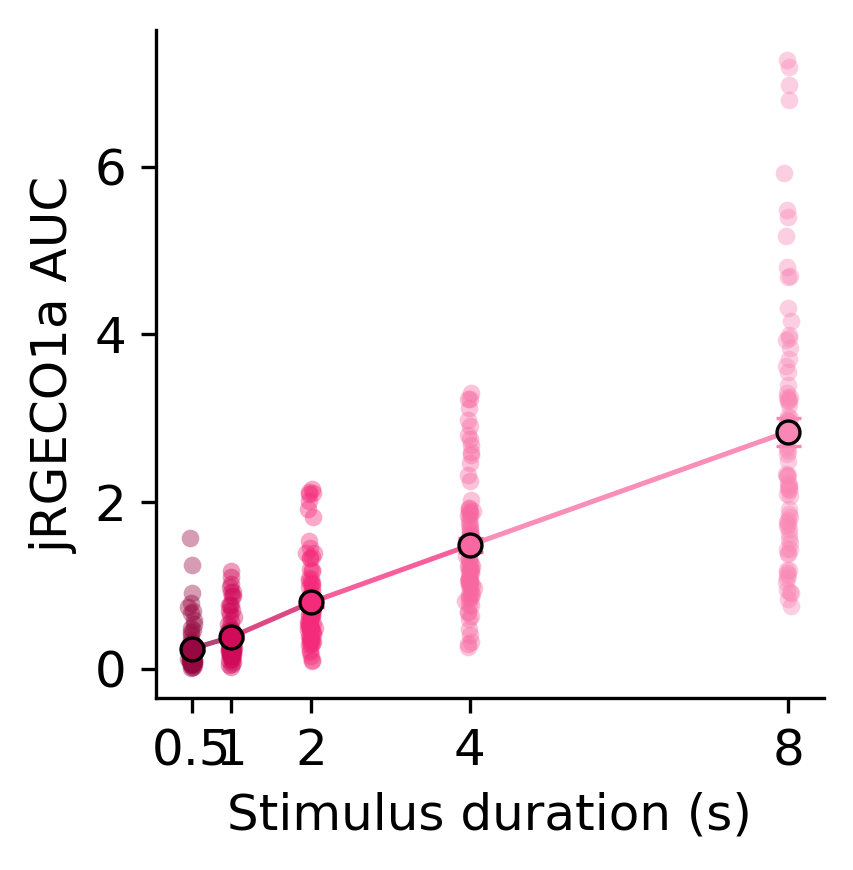

In [49]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    auc_df,
    sensor=CA_SENSOR,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col=AUC_COL,
    color_by="stim_time",
    stim_colors=stim_colors_ca,
    round_stim_to=0.5,
    title="",
    ylabel="jRGECO1a AUC",
    show_legend=False,
)

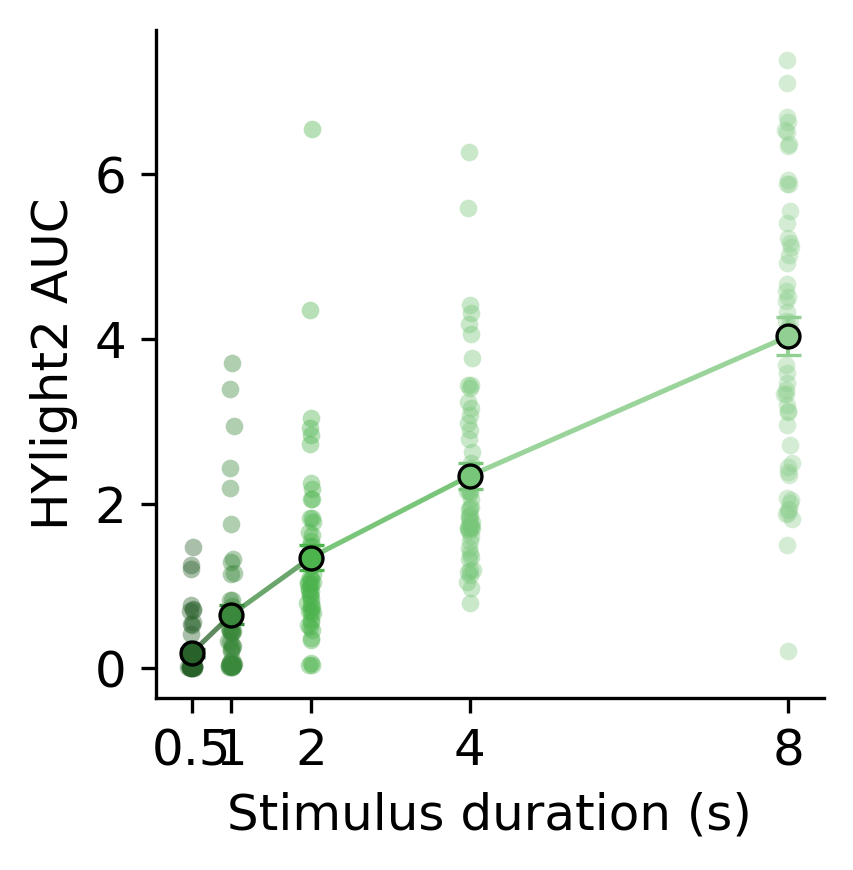

In [52]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    auc_df,
    sensor=HYLIGHT_SENSOR,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col=AUC_COL,
    color_by="stim_time",
    stim_colors=stim_colors_hylight,
    round_stim_to=0.5,
    title="",
    ylabel=f"{HYLIGHT_LABEL} AUC",
    show_legend=False,
)

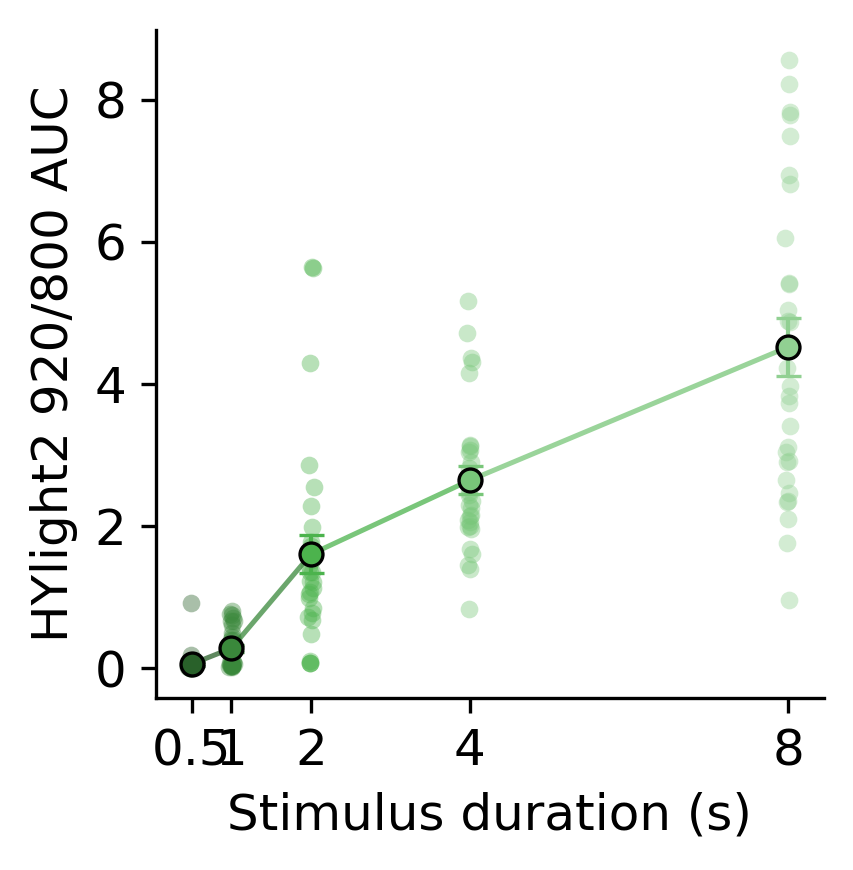

In [53]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    auc_df,
    sensor=RATIO_SENSOR,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col=AUC_COL,
    color_by="stim_time",
    stim_colors=stim_colors_hylight,
    round_stim_to=0.5,
    title="",
    ylabel=f"{HYLIGHT_LABEL} 920/800 AUC",
    show_legend=False,
)

### 6b. AUC relative to Ca

HyLight AUC / Ca AUC:

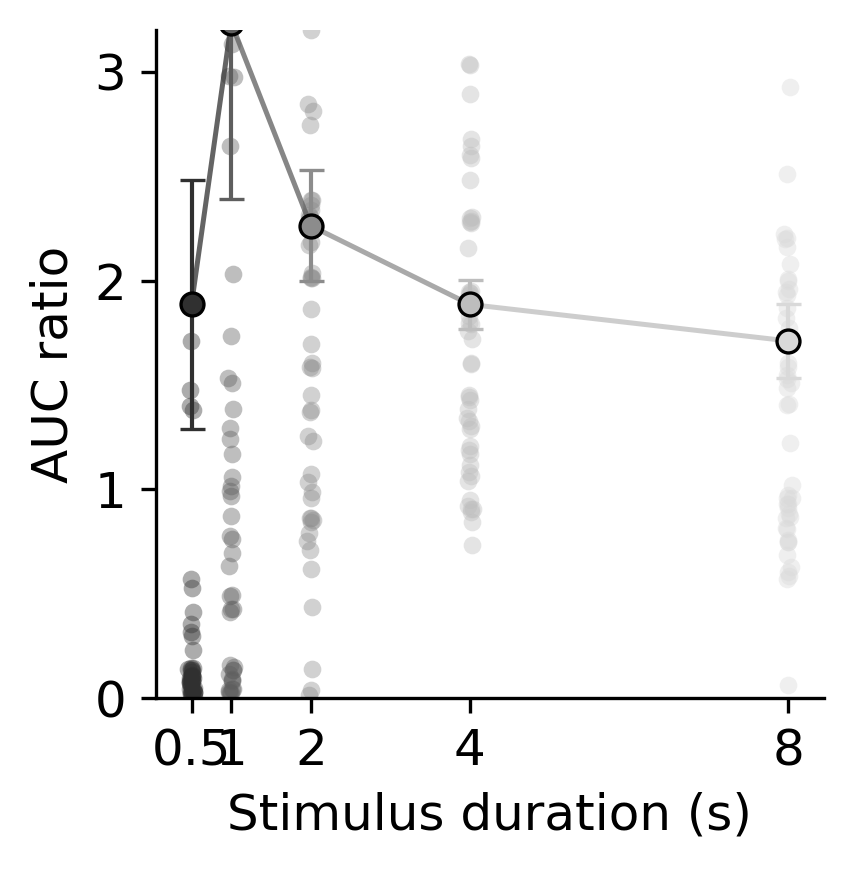

In [54]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    paired_hylight_df,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col="AUC_ratio",
    color_by="stim_time",
    stim_colors=stim_colors_gray,
    round_stim_to=0.5,
    title="",
    ylabel="AUC ratio",
    show_legend=False,
    ylim=(0, 3.2),
)

HyLight 920/800 AUC / Ca AUC:

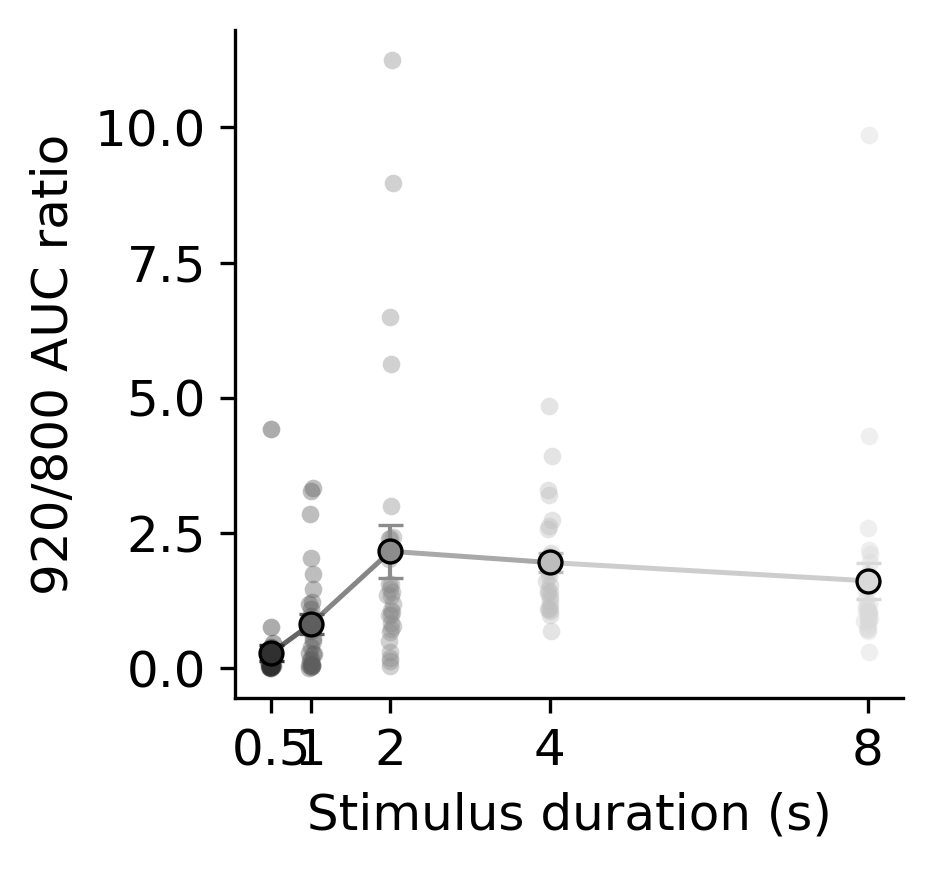

In [55]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    paired_ratio_df,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col="AUC_ratio",
    color_by="stim_time",
    stim_colors=stim_colors_gray,
    round_stim_to=0.5,
    title="",
    ylabel="920/800 AUC ratio",
    show_legend=False,
)

### 6c. HyLight AUC against Ca AUC, one point per neuron

,group,slope,intercept,r,r2,p,slope_stderr,n
0,all,0.688945,0.064874,0.844488,0.713161,3.787906e-50,0.032749,180


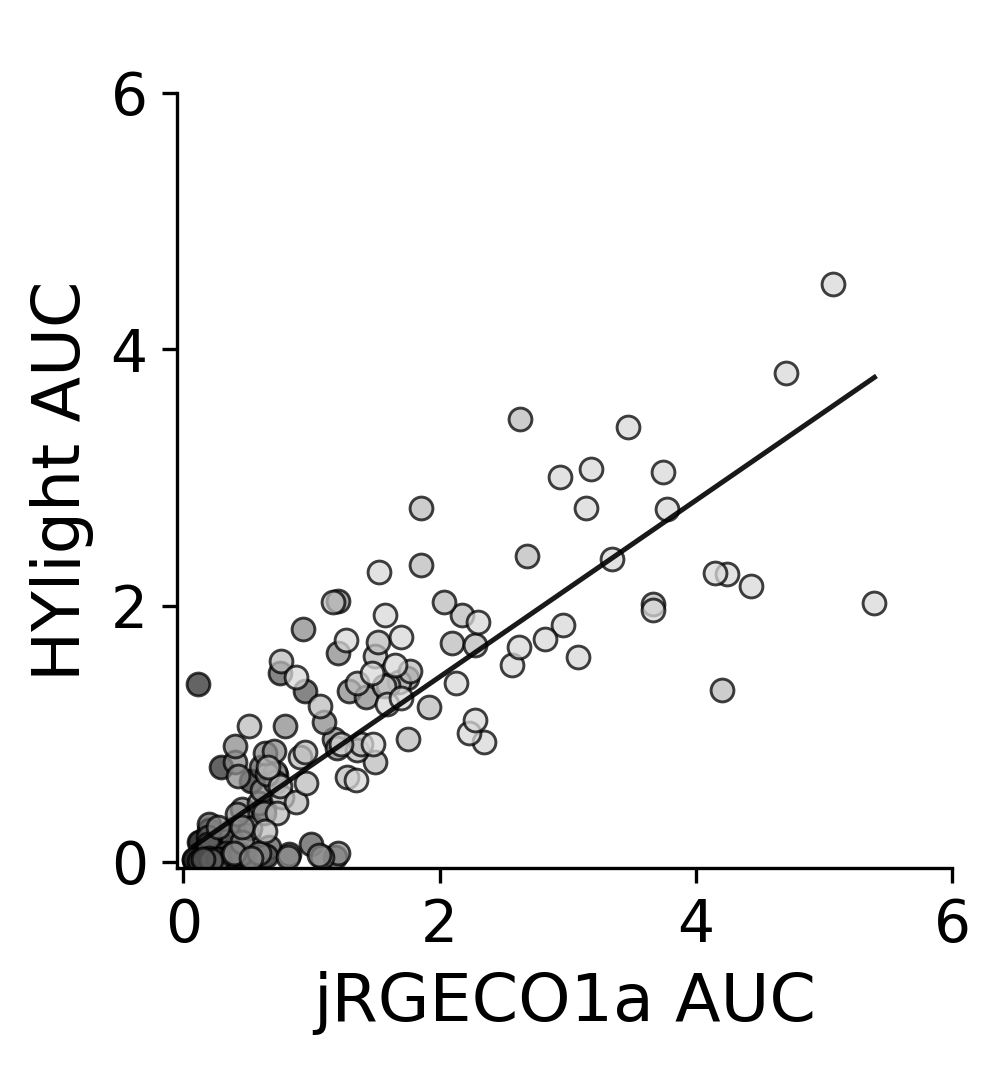

In [33]:
fig, ax, d_plot, fit_stats = plot_hylight_auc_vs_ca_auc(
    paired_hylight_df,
    color_by="stim_time",
    colors=stim_colors_gray,
    stim_times=[0.49, 0.99, 1.99, 3.99, 7.99],
    round_stim_to=0.5,
    genotype="CTR",
    subfolder=[COMPARTMENT],
    point_size=30,
    point_alpha=0.75,
    edgecolor="black",
    edgewidth=0.7,
    title=" ",
    ylim=(-0.05, 6),
    xlim=(-0.05, 6),
    tick_interval=2,
    show_regression=True,
    show_regression_label=True,
    show_identity=False,
    show_legend=False,
    return_fit_stats=True,
    figsize=(5.5, 3.5),
)

ax.set_xlabel("jRGECO1a AUC", fontsize=16)
ax.set_ylabel(f"{HYLIGHT_LABEL} AUC", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
fit_stats

HyLight 920/800 AUC against Ca AUC:

,group,slope,intercept,r,r2,p,slope_stderr,n
0,all,1.005906,-0.085885,0.89175,0.795218,5.529795e-39,0.049119,110


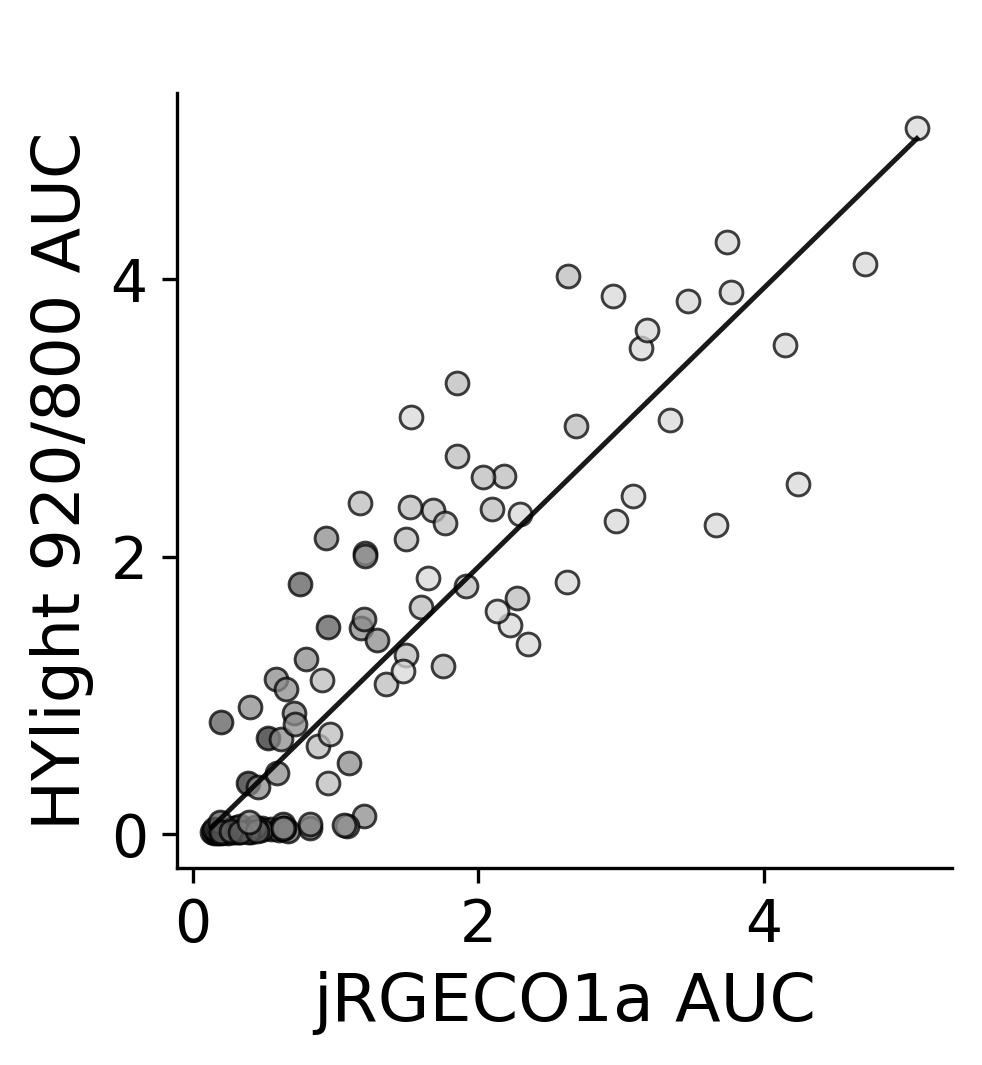

In [34]:
fig, ax, d_plot, fit_stats = plot_hylight_auc_vs_ca_auc(
    paired_ratio_df,
    color_by="stim_time",
    colors=stim_colors_gray,
    stim_times=[0.49, 0.99, 1.99, 3.99, 7.99],
    round_stim_to=0.5,
    genotype="CTR",
    subfolder=[COMPARTMENT],
    point_size=30,
    point_alpha=0.75,
    edgecolor="black",
    edgewidth=0.7,
    title=" ",
    tick_interval=2,
    show_regression=True,
    show_regression_label=True,
    show_identity=False,
    show_legend=False,
    return_fit_stats=True,
    figsize=(5.5, 3.5),
)

ax.set_xlabel("jRGECO1a AUC", fontsize=16)
ax.set_ylabel(f"{HYLIGHT_LABEL} 920/800 AUC", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
fit_stats

### 6d. tPeak by stimulus duration
Only responders have a tPeak. Other columns of `tpeak_df` can be plotted the same way, for example `auc_col="t_first_depolarization_s"`.

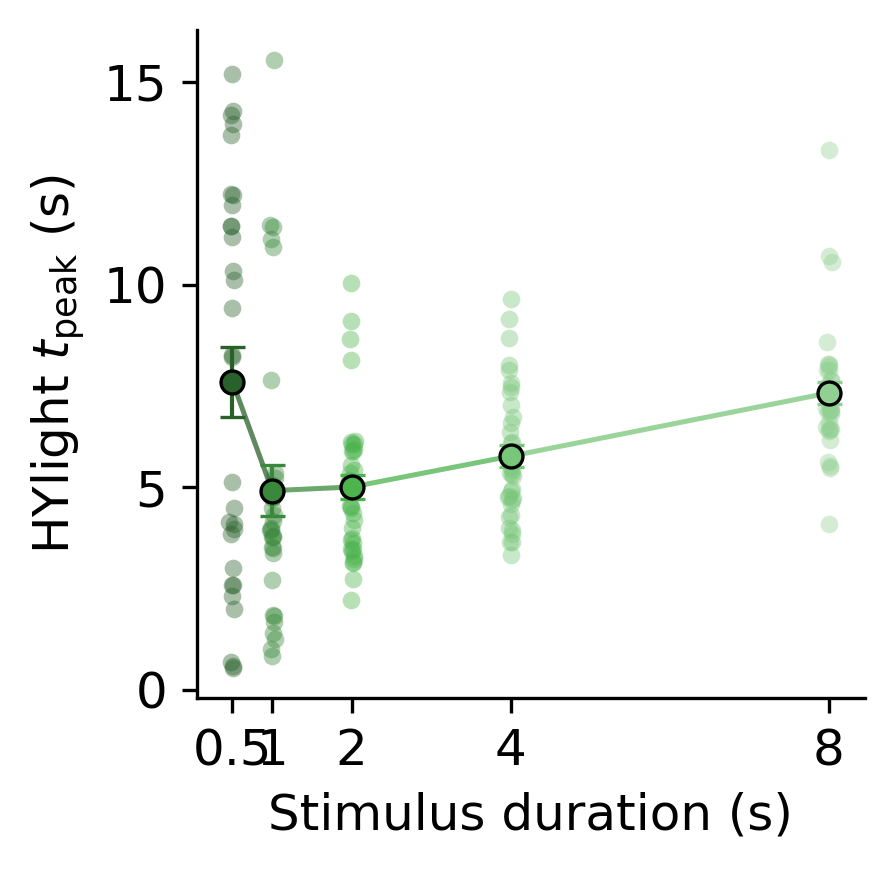

In [35]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    tpeak_df,
    sensor=HYLIGHT_SENSOR,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col="tpeak_s",
    color_by="stim_time",
    stim_colors=stim_colors_hylight,
    round_stim_to=0.5,
    title="",
    ylabel=rf"{HYLIGHT_LABEL} $t_{{\mathrm{{peak}}}}$ (s)",
    show_legend=False,
)

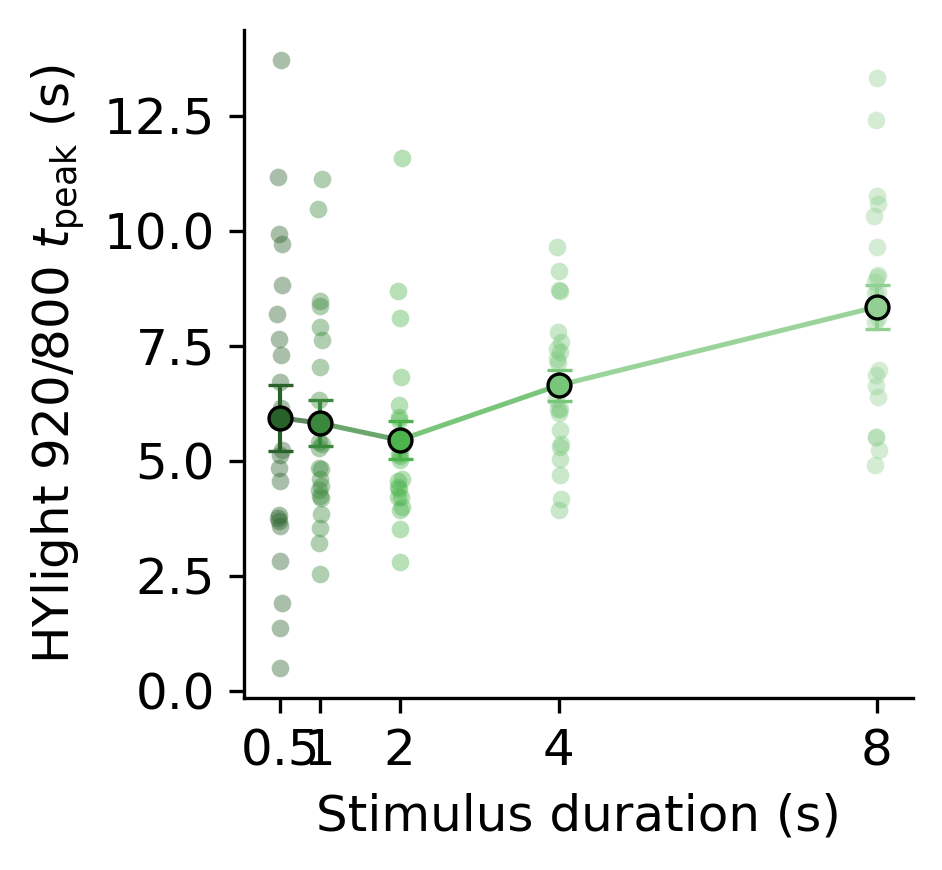

In [36]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    tpeak_df,
    sensor=RATIO_SENSOR,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col="tpeak_s",
    color_by="stim_time",
    stim_colors=stim_colors_hylight,
    round_stim_to=0.5,
    title="",
    ylabel=rf"{HYLIGHT_LABEL} 920/800 $t_{{\mathrm{{peak}}}}$ (s)",
    show_legend=False,
)

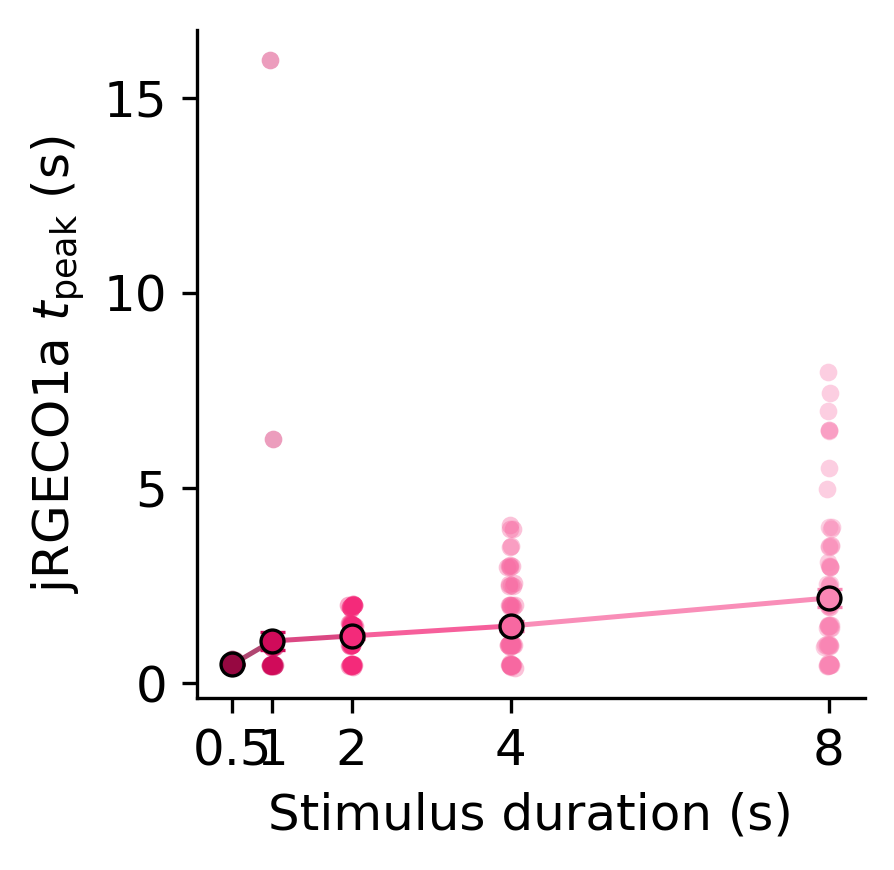

In [37]:
fig, ax, summary, stats_df = plot_auc_by_stim_time_xaxis(
    tpeak_df,
    sensor=CA_SENSOR,
    subfolder=COMPARTMENT,
    genotypes=GENOTYPES,
    genotype_order=GENOTYPES,
    auc_col="tpeak_s",
    color_by="stim_time",
    stim_colors=stim_colors_ca,
    round_stim_to=0.5,
    title="",
    ylabel=r"jRGECO1a $t_{\mathrm{peak}}$ (s)",
    show_legend=False,
)

## 7. Save the tables (optional)

In [ ]:
OUTPUT_DIR = Path("your/path/here")

auc_df.to_csv(OUTPUT_DIR / f"stimlengths_{HYLIGHT_SENSOR}_AUC.csv", index=False)
tpeak_df.to_csv(OUTPUT_DIR / f"stimlengths_{HYLIGHT_SENSOR}_tpeak.csv", index=False)
paired_hylight_df.to_csv(OUTPUT_DIR / f"stimlengths_{HYLIGHT_SENSOR}_AUC_paired_ca.csv", index=False)
paired_ratio_df.to_csv(OUTPUT_DIR / f"stimlengths_{RATIO_SENSOR}_AUC_paired_ca.csv", index=False)
print("Saved to", OUTPUT_DIR)